In [1]:
import pandas as pd

In [2]:
# load data
data = pd.read_csv('./data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
# check data
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# shape of dataset
data.info

<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL 

In [5]:
# statistic summary
data.describe

<bound method NDFrame.describe of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DS

In [6]:
# check missing values
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
# check duplicates
data.duplicated().sum()

0

In [8]:
## find patterns that explain customer churn
# check Churn - distribution 
data['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

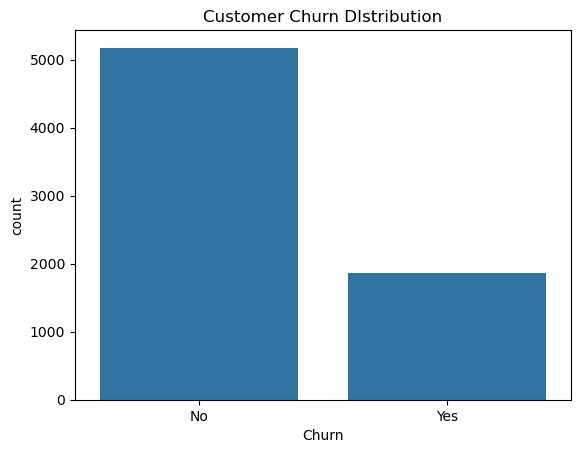

In [9]:
# plot distribution - check if it is balance? how many customers were leaving?
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Churn', data= data)
plt.title('Customer Churn DIstribution')
plt.show()

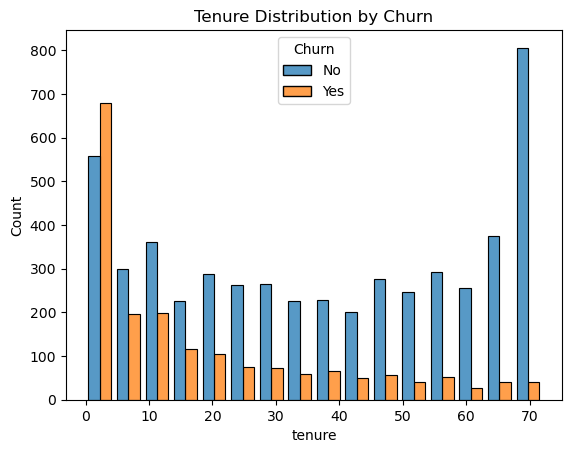

In [10]:
# analyse numerical variables - Tenure, MonthlyCharges, TotalCharges
# Do short-term customers churn more? Do expensive plans increase
sns.histplot(data=data, x='tenure', hue='Churn', multiple="dodge", shrink=.8) #, multiple='stack')
plt.title('Tenure Distribution by Churn')
plt.show()

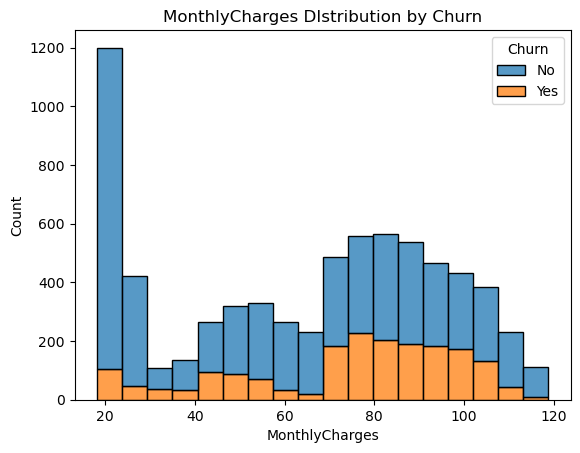

In [11]:
sns.histplot(data = data, x='MonthlyCharges', hue='Churn', multiple='stack')
plt.title('MonthlyCharges DIstribution by Churn')
plt.show()

In [12]:
#sns.histplot(data = data, x='TotalCharges')
d_totalcharges = data['TotalCharges']
d1 = d_totalcharges
# print(np.max(d1))

In [13]:
d1.isnull().sum()

0

In [14]:
print(pd.to_numeric(d1, errors='coerce').min())
# Counts how many items are strings (text), integers, or floats
print(d1.apply(type).value_counts())

18.8
TotalCharges
<class 'str'>    7043
Name: count, dtype: int64


In [15]:
# Convert the column to floats (decimals)
d2 = pd.to_numeric(d1, errors='coerce')
print(d2.apply(type).value_counts())

TotalCharges
<class 'float'>    7043
Name: count, dtype: int64


In [16]:
# Import statistics Library
import statistics as stat
min(d2)

18.8

<function matplotlib.pyplot.show(close=None, block=None)>

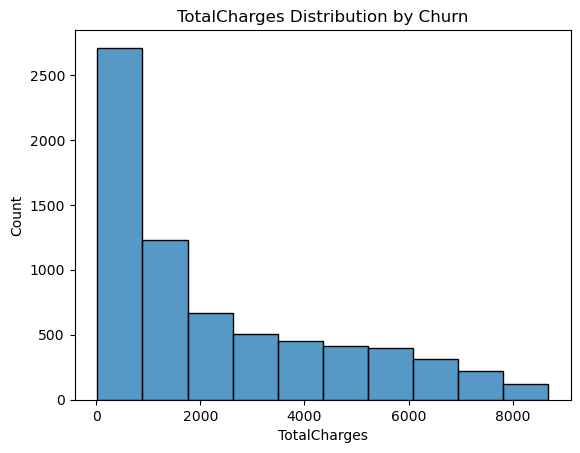

In [17]:
sns.histplot(data=data, x=d2, bins = 10) #bins=range(0, 100, 10))
plt.title('TotalCharges Distribution by Churn')
plt.show

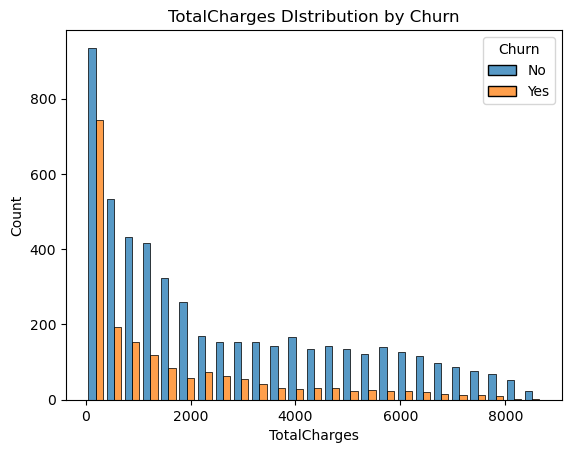

In [18]:
sns.histplot(data = data, x=d2, hue='Churn', multiple="dodge", shrink=.8)
plt.title('TotalCharges DIstribution by Churn')
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

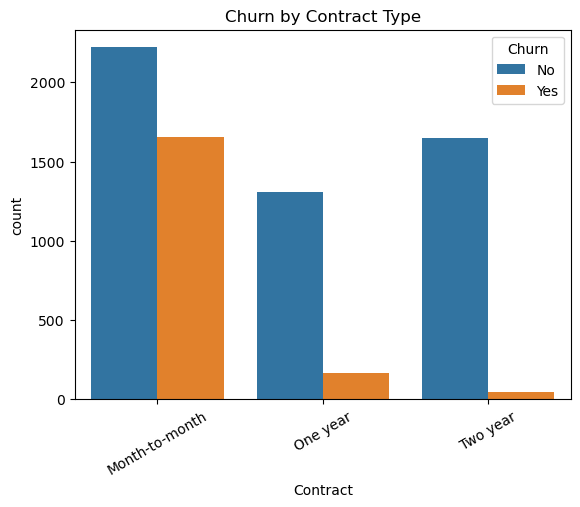

In [19]:
# Analyse categorical variables 
# - Contract, InternetService, PaymentMethod, TechSupport, OnlineSecurity
sns.countplot(x='Contract', hue='Churn', data = data)
plt.xticks(rotation=30)
plt.title('Churn by Contract Type')
plt.show
# -> month-to-month customers churn heavily

<function matplotlib.pyplot.show(close=None, block=None)>

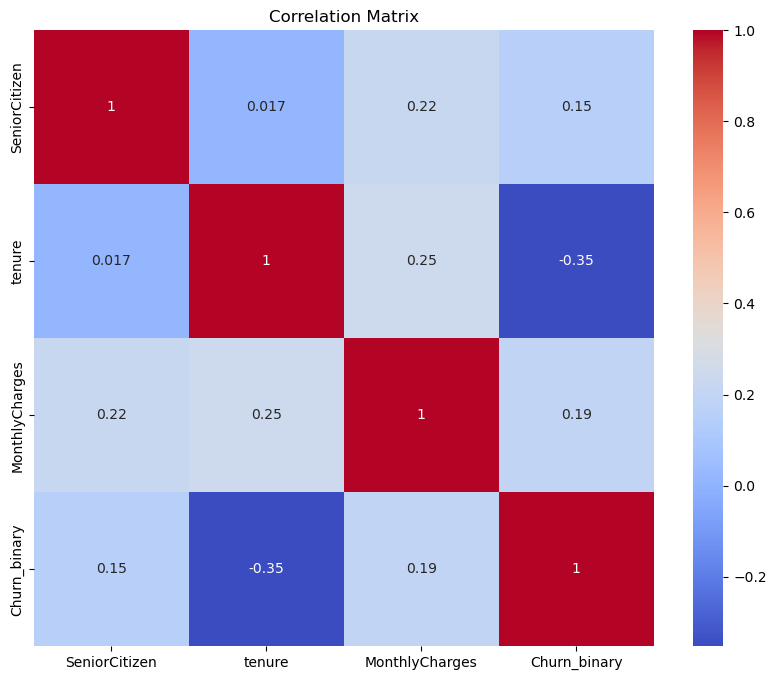

In [20]:
# Correlation analysis
data["Churn_binary"] = data["Churn"].map({"Yes":1, "No":0})

corr = data.corr(numeric_only=True)

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show

In [21]:
# Interpretation of results 1 - 
# Customers with month-to-month contracts showed significantly higher churn rates than customers with yearly contracts.
# Customers with higher monthly charges appeared more likely to churn.

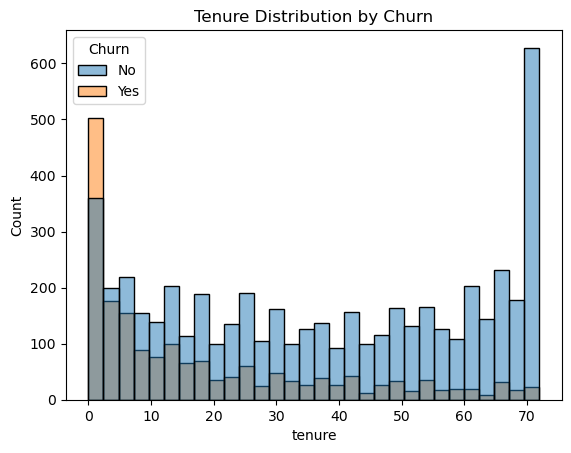

In [21]:
sns.histplot(data=data, x="tenure", hue="Churn", bins=30)

plt.title("Tenure Distribution by Churn")
plt.show()

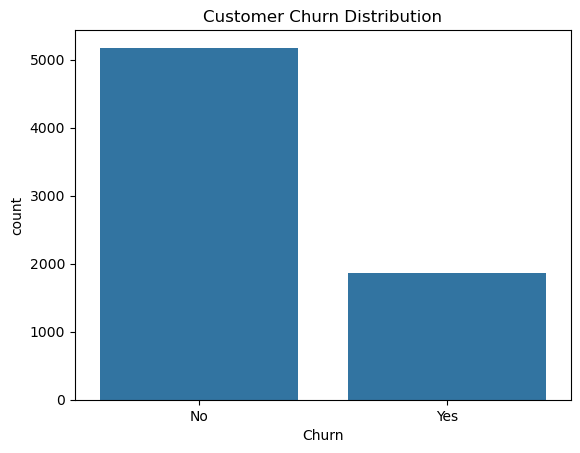

In [22]:
sns.countplot(x="Churn", data=data)
plt.title("Customer Churn Distribution")
plt.show()

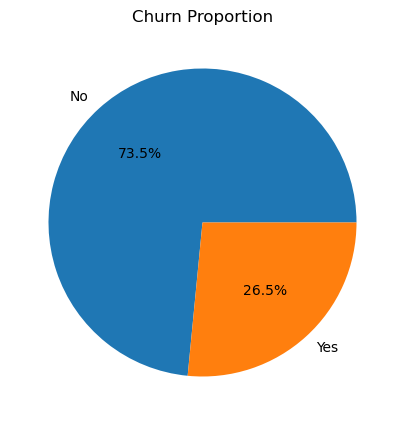

In [23]:
data["Churn"].value_counts().plot.pie(
    autopct='%1.1f%%',
    figsize=(5,5)
)

plt.title("Churn Proportion")
plt.ylabel("")
plt.show()

In [24]:
# Machine Leaning Modeling
# - Predict which customers are likely to churn.
# 1) Logistic Regression
# 2) Random Forest

In [25]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_binary
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.5,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [26]:
# Remove unnecessary columns
df = data.drop(columns = ['customerID', 'Churn_binary'])
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [27]:
# Encode categorical variables -> numerical columns, yes/no
df_encoded = pd.get_dummies(df, drop_first = True)
df_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,...,TotalCharges_996.45,TotalCharges_996.85,TotalCharges_996.95,TotalCharges_997.65,TotalCharges_997.75,TotalCharges_998.1,TotalCharges_999.45,TotalCharges_999.8,TotalCharges_999.9,Churn_Yes
0,0,1,29.85,False,True,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
1,0,34,56.95,True,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,0,2,53.85,True,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,0,45,42.30,True,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,0,2,70.70,False,False,False,True,False,False,True,...,False,False,False,False,False,False,False,False,False,True


In [28]:
# define y target variable
y = df_encoded['Churn_Yes']
y.head()

0    False
1    False
2     True
3    False
4     True
Name: Churn_Yes, dtype: bool

In [29]:
# define X features
X = df_encoded.drop('Churn_Yes', axis = 1)
X.head()

,SeniorCitizen,tenure,MonthlyCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,...,TotalCharges_995.35,TotalCharges_996.45,TotalCharges_996.85,TotalCharges_996.95,TotalCharges_997.65,TotalCharges_997.75,TotalCharges_998.1,TotalCharges_999.45,TotalCharges_999.8,TotalCharges_999.9
0,0,1,29.85,False,True,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
1,0,34,56.95,True,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,0,2,53.85,True,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,0,45,42.30,True,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,0,2,70.70,False,False,False,True,False,False,True,...,False,False,False,False,False,False,False,False,False,False


In [30]:
# Train/test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter = 10000)
model.fit(X_train, y_train)

In [104]:
# Prediction
y_pred = model.predict(X_test)

In [105]:
# Evaluate model
# Accuracy
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.8239886444286728

In [106]:
# Classification report
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.86      0.91      0.88      1036
        True       0.70      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.78      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409



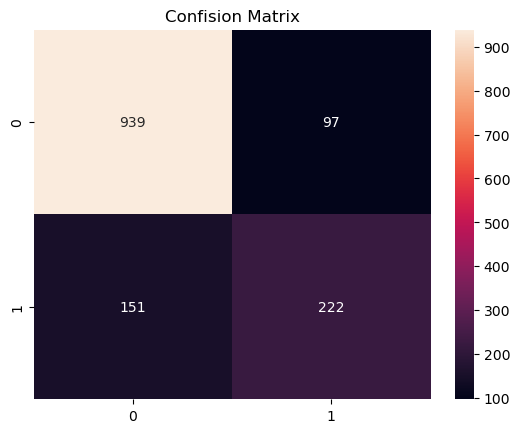

In [107]:
# Confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot = True, fmt = 'd')
plt.title('Confision Matrix')
plt.show()

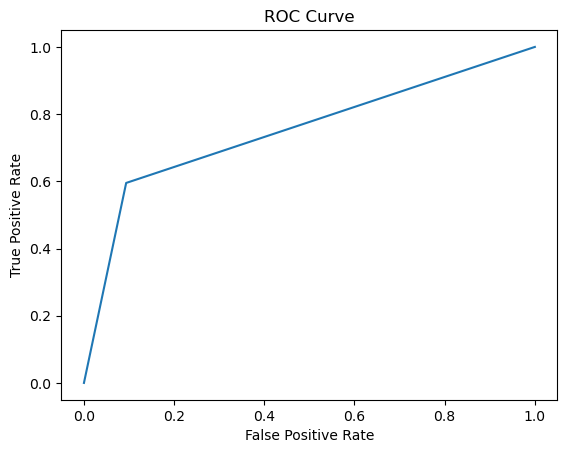

In [108]:
# ROC Curve
from sklearn.metrics import roc_curve, roc_auc_score
y_prob = model.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

In [111]:
# Feature importance
importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

importance.sort_values(by='Coefficient', ascending=False).head(10)

,Feature,Coefficient
1638,TotalCharges_20.2,1.387505
1644,TotalCharges_20.5,1.275087
1521,TotalCharges_19.95,1.202612
1636,TotalCharges_20.1,1.184655
1514,TotalCharges_19.6,1.120111
2516,TotalCharges_288.05,1.092233
3844,TotalCharges_45.3,1.077500
9,InternetService_Fiber optic,1.067190
5755,TotalCharges_740.3,1.033472
4256,TotalCharges_50.45,1.031078


In [113]:
## Random Forest
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [114]:
# Evaluate model
# Accuracy
from sklearn.metrics import accuracy_score
accuracy_score(y_test, rf_pred)

0.7977288857345636

In [115]:
# Classification report
from sklearn.metrics import classification_report
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

       False       0.82      0.92      0.87      1036
        True       0.68      0.45      0.54       373

    accuracy                           0.80      1409
   macro avg       0.75      0.69      0.70      1409
weighted avg       0.78      0.80      0.78      1409



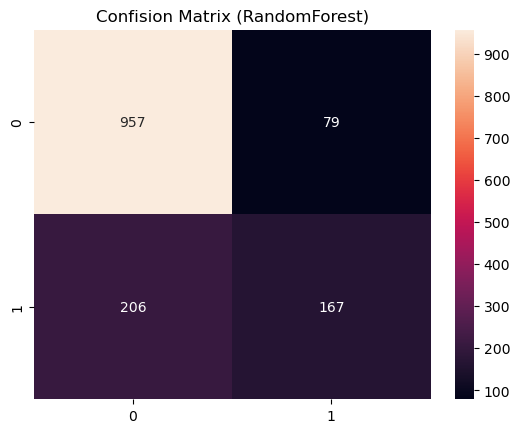

In [116]:
# Confusion matrix
from sklearn.metrics import confusion_matrix
rf_cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(rf_cm, annot = True, fmt = 'd')
plt.title('Confision Matrix (RandomForest)')
plt.show()

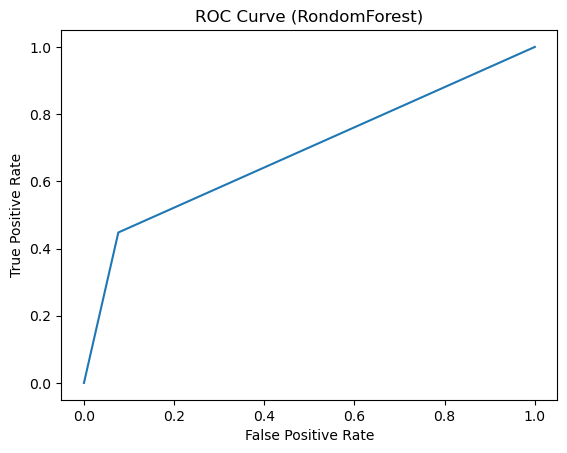

In [117]:
# ROC Curve
from sklearn.metrics import roc_curve, roc_auc_score
y_prob = model.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, rf_pred)
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (RondomForest)')
plt.show()

In [118]:
# Feature importance
importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

importance.sort_values(by='Coefficient', ascending=False).head(10)

,Feature,Coefficient
1638,TotalCharges_20.2,1.387505
1644,TotalCharges_20.5,1.275087
1521,TotalCharges_19.95,1.202612
1636,TotalCharges_20.1,1.184655
1514,TotalCharges_19.6,1.120111
2516,TotalCharges_288.05,1.092233
3844,TotalCharges_45.3,1.077500
9,InternetService_Fiber optic,1.067190
5755,TotalCharges_740.3,1.033472
4256,TotalCharges_50.45,1.031078


In [119]:
df.to_csv("cleaned_churn_data.csv", index=False)